# Day 5: Reorder model

**Question:** for each customer's *next* order, which of the products they've bought before will they buy again?

- **Candidates:** every (customer, product) pair from the customer's past orders.
- **Label:** 1 if that product is in the customer's next order (Instacart's `train` orders), else 0.
- **Features:** built only from orders *before* that next order, plus what is known when the order is placed
  (day, hour, days since the previous order). Nothing from the next order's basket leaks in.
- **Split by customer:** no customer appears in both training and test data.

**Done when:** the model beats the "reorder anything bought at least twice" rule, with the margin logged.

Run on the compute instance (**Python 3.10 - AzureML** kernel). About 15–20 minutes and ~6 GB of memory.

In [1]:
%pip install -q lightgbm

Note: you may need to restart the kernel to use updated packages.


## Setup

In [2]:
import json, os, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score

PROC = os.path.expanduser("~/data/processed/instacart")
OUT = os.path.expanduser("~/runs/day5")
os.makedirs(OUT, exist_ok=True)
USER_FRACTION = 0.5   # share of the 131k labelled customers to use; 0.5 is plenty and keeps it fast
rng = np.random.default_rng(0)

BLUE, INK = "#2a78d6", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e3",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "figure.dpi": 110,
})

orders = pd.read_parquet(f"{PROC}/orders.parquet")
next_lines = pd.read_parquet(f"{PROC}/order_products_train.parquet")
products = pd.read_parquet(f"{PROC}/products.parquet")
t0 = time.time()

## 1. Choose customers and their history
Instacart marks each customer's last order as `train` (basket known: our labels) or `test` (basket hidden).
We use customers with a `train` order.

In [3]:
target = orders[orders.eval_set == "train"]
users = rng.choice(target.user_id.unique(), size=int(target.user_id.nunique() * USER_FRACTION), replace=False)
target = target[target.user_id.isin(users)].set_index("user_id")

hist = orders[(orders.eval_set == "prior") & orders.user_id.isin(users)].sort_values(["user_id", "order_number"])
hist["day"] = hist["days_since_prior_order"].fillna(0).groupby(hist["user_id"]).cumsum()  # days since first order

prior = pd.read_parquet(f"{PROC}/order_products_prior.parquet")
pp = prior.merge(hist[["order_id", "user_id", "order_number", "day"]], on="order_id")
del prior
print(f"{len(users):,} customers, {len(hist):,} past orders, {len(pp):,} past order lines ({time.time() - t0:.0f}s)")

65,604 customers, 1,016,822 past orders, 10,245,444 past order lines (37s)


## 2. Features

In [4]:
# Customer features
u = hist.groupby("user_id").agg(u_orders=("order_number", "max"), u_mean_gap=("days_since_prior_order", "mean"),
                                u_last_day=("day", "max"))
u = u.join(pp.groupby("user_id").agg(u_items=("product_id", "size"), u_distinct=("product_id", "nunique"),
                                     u_reorder_rate=("reordered", "mean")))
u["u_basket"] = u.u_items / u.u_orders
u = u.join(target[["order_dow", "order_hour_of_day", "days_since_prior_order"]].rename(
    columns={"order_dow": "t_dow", "order_hour_of_day": "t_hour", "days_since_prior_order": "t_gap"}))

# Product features (from these customers' past orders)
p = pp.groupby("product_id").agg(p_orders=("order_id", "size"), p_reorder_rate=("reordered", "mean"),
                                 p_cart_pos=("add_to_cart_order", "mean"), p_users=("user_id", "nunique"))
p = p.join(products.set_index("product_id")[["aisle_id", "department_id"]])

# Customer x product features
up = pp.groupby(["user_id", "product_id"]).agg(
    up_orders=("order_id", "size"), up_first=("order_number", "min"), up_last=("order_number", "max"),
    up_cart_pos=("add_to_cart_order", "mean"), up_last_day=("day", "max")).reset_index()
up = up.merge(u, left_on="user_id", right_index=True).merge(p, left_on="product_id", right_index=True)
last3 = pp[pp.order_number > pp.user_id.map(u.u_orders) - 3].groupby(["user_id", "product_id"]).size()
up = up.merge(last3.rename("up_in_last3").reset_index(), on=["user_id", "product_id"], how="left")
up["up_in_last3"] = up.up_in_last3.fillna(0)
up["up_rate"] = up.up_orders / up.u_orders                                   # share of my orders with it
up["up_rate_since_first"] = up.up_orders / (up.u_orders - up.up_first + 1)
up["up_orders_since_last"] = up.u_orders - up.up_last
up["up_days_since_last"] = up.u_last_day - up.up_last_day + up.t_gap.fillna(0)  # as of the next order
up["up_share_of_basket"] = up.up_orders / up.u_items

# Label: is the product in the customer's next order?
nxt = next_lines.merge(target.reset_index()[["order_id", "user_id"]], on="order_id")
up = up.merge(nxt[["user_id", "product_id"]].assign(label=1), on=["user_id", "product_id"], how="left")
up["label"] = up.label.fillna(0).astype("int8")
covered = up.label.sum() / len(nxt)  # share of all next-order items that were bought before

FEATURES = ["u_orders", "u_mean_gap", "u_items", "u_distinct", "u_reorder_rate", "u_basket",
            "t_dow", "t_hour", "t_gap",
            "p_orders", "p_reorder_rate", "p_cart_pos", "p_users", "aisle_id", "department_id",
            "up_orders", "up_cart_pos", "up_in_last3", "up_rate", "up_rate_since_first",
            "up_orders_since_last", "up_days_since_last", "up_share_of_basket"]
up[FEATURES] = up[FEATURES].astype("float32")
print(f"{len(up):,} candidate pairs, {up.label.mean():.1%} reordered | "
      f"{len(FEATURES)} features | {time.time() - t0:.0f}s")
print(f"Candidates cover {covered:.0%} of items in next orders; the rest are first-time purchases, "
      f"which a history-based model can't predict")

4,219,624 candidate pairs, 9.8% reordered | 23 features | 60s
Candidates cover 60% of items in next orders; the rest are first-time purchases, which a history-based model can't predict


## 3. Split by customer: 70% train, 10% validation (early stopping, threshold), 20% test

In [5]:
perm = rng.permutation(users)
n = len(perm)
part = pd.Series(np.select([np.arange(n) < 0.7 * n, np.arange(n) < 0.8 * n], ["train", "valid"], "test"),
                 index=perm)
up["split"] = up.user_id.map(part)
tr, va, te = (up[up.split == s] for s in ["train", "valid", "test"])
print({s: f"{(up.split == s).sum():,} rows" for s in ["train", "valid", "test"]})

{'train': '2,950,582 rows', 'valid': '422,081 rows', 'test': '846,961 rows'}


## 4. Train LightGBM

In [6]:
PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_data_in_leaf=200,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              num_threads=4, verbose=-1, seed=0)
cats = ["aisle_id", "department_id"]
dtr = lgb.Dataset(tr[FEATURES], tr.label, categorical_feature=cats, free_raw_data=False)
dva = lgb.Dataset(va[FEATURES], va.label, categorical_feature=cats, reference=dtr)
t1 = time.time()
model = lgb.train(PARAMS, dtr, num_boost_round=2000, valid_sets=[dva], valid_names=["valid"],
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
print(f"Best round {model.best_iteration}, trained in {time.time() - t1:.0f}s")

Training until validation scores don't improve for 50 rounds
[100]	valid's binary_logloss: 0.244869
[200]	valid's binary_logloss: 0.244291
[300]	valid's binary_logloss: 0.244199
[400]	valid's binary_logloss: 0.244163
Early stopping, best iteration is:
[415]	valid's binary_logloss: 0.244149
Best round 415, trained in 175s


## 5. Compare with simple rules (on the test customers)
- **Bought-twice rule:** predict "reorder" if the customer bought the product at least twice before.
- **Habit score:** the share of the customer's orders that contained the product (a strong, simple baseline).
- **Model:** LightGBM probability.

For F1, each method's threshold is chosen on the **validation** customers, then applied unchanged to test.

In [7]:
def best_threshold(y, score):
    prec, rec, thr = precision_recall_curve(y, score)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    return thr[np.argmax(f1[:-1])]


va_pred = model.predict(va[FEATURES], num_iteration=model.best_iteration)
te_pred = model.predict(te[FEATURES], num_iteration=model.best_iteration)
thr_model, thr_habit = best_threshold(va.label, va_pred), best_threshold(va.label, va.up_rate)

rows = []
for name, score, pred in [
    ("Bought-twice rule", te.up_orders, te.up_orders >= 2),
    ("Habit score (share of orders)", te.up_rate, te.up_rate >= thr_habit),
    ("LightGBM model", te_pred, te_pred >= thr_model),
]:
    rows.append({"method": name, "AUC": roc_auc_score(te.label, score), "F1": f1_score(te.label, pred),
                 "precision": precision_score(te.label, pred), "recall": recall_score(te.label, pred)})
results = pd.DataFrame(rows).set_index("method")
margin = {
    "auc_gain_vs_rule": results.loc["LightGBM model", "AUC"] - results.loc["Bought-twice rule", "AUC"],
    "f1_gain_vs_rule": results.loc["LightGBM model", "F1"] - results.loc["Bought-twice rule", "F1"],
    "f1_gain_vs_habit": results.loc["LightGBM model", "F1"] - results.loc["Habit score (share of orders)", "F1"],
}
print(f"Test: {te.user_id.nunique():,} customers, {len(te):,} candidate pairs, {te.label.mean():.1%} positive")
print({k: round(v, 3) for k, v in margin.items()})
results.round(3)

Test: 13,120 customers, 846,961 candidate pairs, 9.7% positive
{'auc_gain_vs_rule': 0.125, 'f1_gain_vs_rule': 0.169, 'f1_gain_vs_habit': 0.072}


,AUC,F1,precision,recall
method,,,,
Bought-twice rule,0.711,0.277,0.172,0.711
Habit score (share of orders),0.771,0.374,0.384,0.364
LightGBM model,0.835,0.446,0.409,0.491


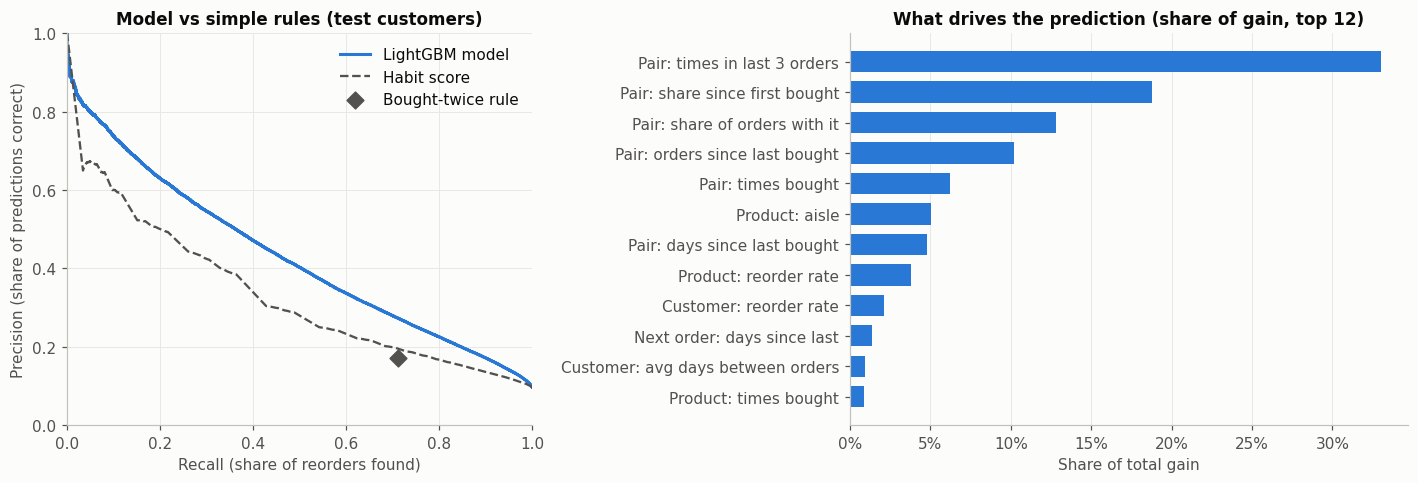

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.2]})

ax = axes[0]
for name, score, style in [("LightGBM model", te_pred, dict(color=BLUE, linewidth=2)),
                           ("Habit score", te.up_rate, dict(color=INK, linewidth=1.5, linestyle="--"))]:
    prec, rec, _ = precision_recall_curve(te.label, score)
    ax.plot(rec, prec, label=name, **style)
r = results.loc["Bought-twice rule"]
ax.scatter([r.recall], [r.precision], s=60, color=INK, marker="D", zorder=3, label="Bought-twice rule")
ax.set(xlabel="Recall (share of reorders found)", ylabel="Precision (share of predictions correct)",
       title="Model vs simple rules (test customers)", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False)

ax = axes[1]
NICE = {"u_orders": "Customer: orders placed", "u_mean_gap": "Customer: avg days between orders",
        "u_items": "Customer: items bought", "u_distinct": "Customer: distinct products",
        "u_reorder_rate": "Customer: reorder rate", "u_basket": "Customer: avg basket size",
        "t_dow": "Next order: weekday", "t_hour": "Next order: hour", "t_gap": "Next order: days since last",
        "p_orders": "Product: times bought", "p_reorder_rate": "Product: reorder rate",
        "p_cart_pos": "Product: avg cart position", "p_users": "Product: buyers",
        "aisle_id": "Product: aisle", "department_id": "Product: department",
        "up_orders": "Pair: times bought", "up_cart_pos": "Pair: avg cart position",
        "up_in_last3": "Pair: times in last 3 orders", "up_rate": "Pair: share of orders with it",
        "up_rate_since_first": "Pair: share since first bought", "up_orders_since_last": "Pair: orders since last bought",
        "up_days_since_last": "Pair: days since last bought", "up_share_of_basket": "Pair: share of all items"}
imp = pd.Series(model.feature_importance("gain"), index=[NICE[f] for f in FEATURES]).nlargest(12)[::-1]
ax.barh(imp.index, imp / imp.sum(), height=0.7, color=BLUE)
ax.set(title="What drives the prediction (share of gain, top 12)", xlabel="Share of total gain")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(f"{OUT}/model_vs_rules.png", bbox_inches="tight"); plt.show()

## 6. Product demand signal for Day 6
For each product, the model's **expected reorders**: the sum of predicted probabilities over the customers who
have bought it, using only the validation and test customers (the model never trained on them).
Divided by the number of those customers, it reads as "expected repeat purchases per 1,000 next orders".
The check below compares it with what actually happened.

In [9]:
held = pd.concat([va.assign(pred=va_pred), te.assign(pred=te_pred)])
n_held = held.user_id.nunique()
demand = held.groupby("product_id").agg(expected_reorders=("pred", "sum"), actual_reorders=("label", "sum"),
                                        past_buyers=("pred", "size"))
demand["demand_per_1000_orders"] = demand.expected_reorders / n_held * 1000
demand = demand.join(products.set_index("product_id")[["product_name", "aisle"]]).sort_values(
    "expected_reorders", ascending=False)

corr = np.corrcoef(demand.expected_reorders, demand.actual_reorders)[0, 1]
print(f"Expected vs actual reorders: total {demand.expected_reorders.sum():,.0f} vs "
      f"{demand.actual_reorders.sum():,.0f}; per-product correlation {corr:.3f}")
demand.reset_index().to_parquet(f"{OUT}/product_demand.parquet", index=False)
demand.head(10)[["product_name", "aisle", "past_buyers", "expected_reorders",
                 "actual_reorders", "demand_per_1000_orders"]].round(1)

Expected vs actual reorders: total 123,634 vs 123,073; per-product correlation 0.997


,product_name,aisle,past_buyers,expected_reorders,actual_reorders,demand_per_1000_orders
product_id,,,,,,
24852,Banana,fresh fruits,6969,2439.0,2474,123.9
13176,Bag of Organic Bananas,fresh fruits,6045,1995.6,1939,101.4
21137,Organic Strawberries,fresh fruits,5590,1287.3,1317,65.4
21903,Organic Baby Spinach,packaged vegetables fruits,5203,1175.6,1175,59.7
47209,Organic Hass Avocado,fresh fruits,4070,940.5,910,47.8
47766,Organic Avocado,fresh fruits,3999,904.3,916,45.9
47626,Large Lemon,fresh fruits,4344,853.6,855,43.4
16797,Strawberries,fresh fruits,4154,738.2,750,37.5
26209,Limes,fresh fruits,4276,671.1,664,34.1


## 7. Save and log to Azure ML

In [10]:
model.save_model(f"{OUT}/reorder_lgbm.txt", num_iteration=model.best_iteration)
summary = {"customers": int(len(users)), "candidate_pairs": int(len(up)), "best_iteration": int(model.best_iteration),
           "threshold_model": float(thr_model), "candidate_coverage": float(covered),
           "results": results.round(4).to_dict(orient="index"), "margin": {k: float(v) for k, v in margin.items()}}
with open(f"{OUT}/reorder_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)

try:  # needs the compute instance's sign-in (click JupyterLab once if it fails)
    import mlflow
    uri = subprocess.run(["az", "ml", "workspace", "show", "-n", "mlw-retail", "-g", "rg-retail",
                          "--query", "mlflow_tracking_uri", "-o", "tsv"],
                         capture_output=True, text=True, timeout=120).stdout.strip()
    mlflow.set_tracking_uri(uri)
    mlflow.set_experiment("reorder-model")
    with mlflow.start_run(run_name="lgbm-v1"):
        mlflow.log_params({**PARAMS, "user_fraction": USER_FRACTION, "best_iteration": model.best_iteration,
                           "features": len(FEATURES)})
        mlflow.log_metrics({f"test_{m.lower()}_{k}".replace(" ", "_"): float(v)
                            for k, row in results.iterrows() for m, v in row.items()
                            if k == "LightGBM model"} | {k: float(v) for k, v in margin.items()})
        for f in ["model_vs_rules.png", "reorder_metrics.json", "reorder_lgbm.txt"]:
            mlflow.log_artifact(f"{OUT}/{f}")
    print("Logged to Azure ML experiment 'reorder-model'")
except Exception as e:
    print("MLflow logging skipped:", str(e)[:200])

print(sorted(os.listdir(OUT)))

2026/11/11 04:10:16 INFO mlflow.tracking.fluent: Experiment with name 'reorder-model' does not exist. Creating a new experiment.


🏃 View run lgbm-v1 at: https://australiaeast.api.azureml.ms/mlflow/v2.0/subscriptions/54672b6a-6e54-4d3c-8ca0-47882e3651ef/resourceGroups/rg-retail/providers/Microsoft.MachineLearningServices/workspaces/mlw-retail/#/experiments/2bf8100c-7028-481e-a540-cbf366db7b82/runs/11ddc99a-8904-4010-8e43-7d4a01237092
🧪 View experiment at: https://australiaeast.api.azureml.ms/mlflow/v2.0/subscriptions/54672b6a-6e54-4d3c-8ca0-47882e3651ef/resourceGroups/rg-retail/providers/Microsoft.MachineLearningServices/workspaces/mlw-retail/#/experiments/2bf8100c-7028-481e-a540-cbf366db7b82
Logged to Azure ML experiment 'reorder-model'
['model_vs_rules.png', 'product_demand.parquet', 'reorder_lgbm.txt', 'reorder_metrics.json']


Back up (terminal):
```bash
azcopy copy "$HOME/runs/day5" "https://stretail26561.blob.core.windows.net/retail-data/outputs/" --recursive
```

## Notes for LOG.md
- AUC and F1 for the rule, the habit score and the model, and the margin.
- The top 3 features and what they mean in plain words.
- The candidate coverage (the share of next-order reorders the setup can predict at all).